# RAG: Baseline Retrieval vs. Cross-Encoder Re-Ranking

**Document:** The Laws of Cricket (MCC, 2017 Code, 4th Edition, 2026), 90-page PDF with 42 Laws full of exceptions, restrictions and formal wording.
**Goal:** build two retrieval pipelines over the *same* chunk corpus and show where a Cross-Encoder re-ranker fixes the mistakes of a Bi-Encoder.

| | Pipeline 1 - Baseline | Pipeline 2 - Re-Ranking |
|---|---|---|
| Stage 1 | Bi-Encoder (`all-MiniLM-L6-v2`) + FAISS, Top-10 by cosine similarity | *same Top-10* |
| Stage 2 | - | Cross-Encoder (`ms-marco-MiniLM-L-6-v2`) scores all 10 `(query, chunk)` pairs, re-sort |
| Context to LLM | Top-3 by cosine | Top-3 by Cross-Encoder score |
| Generator | `Qwen2.5-3B-Instruct` (local, open weights), identical prompt | same |

```
query -> Bi-Encoder -> FAISS top-10 --+--> take top-3 ------------------------> LLM -> Answer 1   (Pipeline 1)
                                      +--> Cross-Encoder -> re-sort -> top-3 --> LLM -> Answer 2   (Pipeline 2)
```

**Notebook outline**
1. Setup & configuration
2. Load the PDF and clean it
3. Parse the legal structure (Laws and clauses)
4. Chunking
5. Pipeline 1 - Bi-Encoder index + baseline retrieval
6. Pipeline 2 - Cross-Encoder re-ranking
7. LLM generation with one shared prompt
8. Failure-mode analysis (stress tests) with rank shifts and Answer 1 vs Answer 2
9. Where re-ranking does *not* help (honest counter-examples)
10. Retrieval quality on a larger labelled query set
11. Latency profiling
12. Scaling: why not run the Cross-Encoder over everything?
13. Save outputs
14. Summary

> Run on Google Colab with a **T4 GPU** (Runtime > Change runtime type). The PDF is downloaded automatically in Section 1.

## 1. Setup & configuration

In [1]:
!pip install -q pypdf sentence-transformers faiss-cpu transformers accelerate torch pandas numpy matplotlib

In [34]:
import json
import re
import time
import platform
import urllib.request
from dataclasses import dataclass
from pathlib import Path

import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
import sentence_transformers
from IPython.display import display, Markdown
from pypdf import PdfReader
from sentence_transformers import CrossEncoder, SentenceTransformer
from transformers import AutoModelForCausalLM, AutoTokenizer

# ---- configuration (everything tunable lives here) ----
PDF_URL = "https://www.lords.org/getmedia/1d908298-5c44-468d-b6a7-e1414a1296e0/Laws-of-Cricket-2017-Code-4th-Edition-(2026)_3.pdf"
PDF_PATH = Path("Laws-of-Cricket-2017-Code-4th-Edition-2026.pdf")   # or upload your own copy with this name
RESULTS_DIR = Path("results_final")
BI_ENCODER_NAME = "sentence-transformers/all-MiniLM-L6-v2"   # dense Bi-Encoder, 384-dim
CROSS_ENCODER_NAME = "cross-encoder/ms-marco-MiniLM-L-6-v2"  # Cross-Encoder re-ranker named in the brief
LLM_NAME = "Qwen/Qwen2.5-3B-Instruct"                        # local open-weights generator (use Qwen2.5-1.5B-Instruct if memory is tight)
TOP_K = 10             # candidates from the first stage
TOP_N = 3              # chunks passed to the LLM
MAX_CHUNK_CHARS = 900  # keeps every chunk under the Bi-Encoder's 256-token window
MAX_NEW_TOKENS = 200
SEED = 0
RETRIEVAL_DEVICE = "cpu"                                     # Bi/Cross-Encoder on CPU = realistic serving latency
LLM_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

RESULTS_DIR.mkdir(exist_ok=True)
torch.manual_seed(SEED)
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

if not PDF_PATH.exists():   # fetch the Laws once
    req = urllib.request.Request(PDF_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as r, open(PDF_PATH, "wb") as f:
        f.write(r.read())
print(f"python {platform.python_version()} | torch {torch.__version__} | transformers {transformers.__version__} "
      f"| sentence-transformers {sentence_transformers.__version__} | faiss {faiss.__version__}")
print(f"LLM device: {LLM_DEVICE} | retrieval models on: {RETRIEVAL_DEVICE} | PDF: {PDF_PATH} ({PDF_PATH.stat().st_size / 1e6:.2f} MB)")

python 3.10.20 | torch 2.5.1+cu124 | transformers 5.12.1 | sentence-transformers 5.5.1 | faiss 1.15.1
LLM device: cuda | retrieval models on: cpu | PDF: Laws-of-Cricket-2017-Code-4th-Edition-2026.pdf (0.88 MB)


In [3]:
# Plot style shared by every figure. Colour = pipeline identity (blue = baseline, orange = re-ranked).
C_BASE, C_RERANK = "#2a78d6", "#eb6834"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.bbox": "tight",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "font.size": 9.5, "legend.frameon": False, "axes.axisbelow": True,
})

## 2. Load the PDF and clean it

The PDF is a booklet: every PDF page holds two printed pages, and each one starts with a page-number line such as `28 29`. That line (and non-breaking spaces / soft hyphens) would pollute the chunks, so it is removed before anything else.

In [4]:
def load_pdf_text(path):
    # Return the whole document as one clean string, plus the number of PDF pages.
    reader = PdfReader(str(path))
    pages = []
    for p in reader.pages:
        t = (p.extract_text() or "").replace("\xa0", " ").replace("\u00ad", "")
        t = re.sub(r"^\s*\d{1,3}\s+\d{1,3}\s*\n", "", t)   # booklet page numbers such as "28 29"
        pages.append(t)
    return "\n".join(pages), len(pages)


text, n_pages = load_pdf_text(PDF_PATH)
print(f"{n_pages} pages -> {len(text.split()):,} words, {len(text):,} characters")
print(text[text.index("LAW 21 NO BALL"):][:450])

90 pages -> 40,075 words, 231,250 characters
LAW 21 NO BALL
21.1  Mode of delivery
21.1.1  The umpire shall ascertain whether the bowler intends to 
bowl right-handed or left-handed, over or round the wicket, 
and shall so inform the striker.
It is unfair if the bowler fails to notify the umpire of a change 
in mode of delivery. In this case the umpire shall call and 
signal No ball.
21.1.2  Underarm bowling shall not be permitted except by special 
agreement before the match.
21.2  Fair de


## 3. Parse the legal structure

The Laws have a clean two-level structure:

* **42 Laws** - each starts with a heading such as `LAW 21 NO BALL` (the preamble, contents page and appendices are left out).
* **Numbered clauses** inside each Law - `21.5 Fair delivery - the feet`, with sub-clauses `21.5.1`, `21.5.2`, ...

Splitting by Law first means no chunk ever mixes two Laws. This matters here: many Laws repeat the same words (*ball*, *bowler*, *umpire*, *penalty runs*), so a chunk that does not say which Law it belongs to is easy to confuse with another.

In [5]:
@dataclass
class Law:
    number: int
    title: str
    body: str


def split_laws(text):
    # Body headings are upper case ("LAW 21 NO BALL"); the contents page uses title case, so it is skipped automatically.
    heads = list(re.finditer(r"^LAW (\d{1,2}) ([A-Z][A-Z’'\-;, ]+?)\s*$", text, re.M))
    app = re.search(r"^APPENDIX A\b", text[heads[-1].end():], re.M)           # Law 42 ends where Appendix A starts
    end_all = heads[-1].end() + app.start() if app else len(text)
    laws = []
    for k, m in enumerate(heads):
        end = heads[k + 1].start() if k + 1 < len(heads) else end_all
        laws.append(Law(int(m.group(1)), m.group(2).strip().capitalize(), text[m.end():end].strip("\n")))
    return laws


def split_clauses(law):
    # Top-level clauses look like "21.5  Fair delivery"; the number must start with the Law number.
    pat = re.compile(rf"^({law.number}\.\d{{1,2}})\s+(\S.*)$")
    clauses, cur = [], None
    for ln in law.body.split("\n"):
        m = pat.match(ln)
        if m and not re.match(rf"^{law.number}\.\d{{1,2}}\.\d", ln):
            cur = {"no": m.group(1), "title": m.group(2).strip(), "lines": []}
            clauses.append(cur)
        elif cur is not None:
            cur["lines"].append(ln)
    return clauses


laws = split_laws(text)
assert [l.number for l in laws] == list(range(1, 43)), "expected Laws 1..42"
print(f"{len(laws)} Laws, {sum(len(split_clauses(l)) for l in laws)} top-level clauses")
law21 = laws[20]
print(f"\nLaw {law21.number} - {law21.title}: clauses = {[c['no'] + ' ' + c['title'] for c in split_clauses(law21)][:6]} ...")

42 Laws, 278 top-level clauses

Law 21 - No ball: clauses = ['21.1 Mode of delivery', '21.2 Fair delivery – the arm', '21.3 Ball thrown or delivered underarm – action by umpires', '21.4 Bowler throwing towards striker’ s end before delivery', '21.5 Fair delivery – the feet', '21.6 Bowler breaking wicket in delivering ball'] ...


## 4. Chunking

**Strategy: structure-aware chunks whose body is at most ~900 characters (about 200 tokens), plus a one-line header.**

* A clause is split at its sub-clauses (`21.5.1`, `21.5.2`, ...); a very long sub-clause is split at sentence boundaries.
* Consecutive short pieces *of the same Law* are packed together up to the limit.
* Every chunk starts with a header such as `Laws of Cricket, Law 21 (No ball)`, so a chunk that only holds clause 21.12 still says which Law it is from.
* Each chunk keeps a readable reference (`Law 21.5`, `Law 21.12-21.14`) used in the rank tables and in LLM citations.

Every chunk fits inside the 256 word-piece window of `all-MiniLM-L6-v2`, so nothing is silently truncated (checked in Section 5).

In [6]:
def _flow(lines):
    # Join hard-wrapped PDF lines into one paragraph.
    return re.sub(r"\s+", " ", " ".join(lines)).strip()


def _units(clause):
    # Split a clause into sub-clause units ("21.5.1 ...") so long clauses can be cut at natural points.
    units, buf = [], [f"{clause['no']} {clause['title']}"]
    for ln in clause["lines"]:
        if re.match(r"^\d{1,2}\.\d{1,2}\.\d{1,2}(\.\d{1,2})*\s", ln) and buf:
            units.append(_flow(buf))
            buf = []
        buf.append(ln)
    units.append(_flow(buf))
    return units


def _split_long(text, max_chars):
    # Split an over-long unit on sentence / list-point boundaries and pack the pieces greedily.
    pieces = re.split(r"(?<=[.;:])\s+(?=[A-Z(])", text)
    out, cur = [], ""
    for p in pieces:
        if cur and len(cur) + 1 + len(p) > max_chars:
            out.append(cur)
            cur = p
        else:
            cur = f"{cur} {p}".strip()
    if cur:
        out.append(cur)
    return out


def chunk_laws(laws, max_chars=MAX_CHUNK_CHARS):
    chunks = []
    for law in laws:
        pieces = []                                   # (clause number, text) in reading order
        for cl in split_clauses(law):
            for unit in _units(cl):
                for part in _split_long(unit, max_chars):
                    pieces.append((cl["no"], part))
        buf, nos = "", []

        def flush():
            nonlocal buf, nos
            if not buf:
                return
            first, last = nos[0], nos[-1]
            ref = f"Law {first}" if first == last else f"Law {first}-{last}"
            header = f"Laws of Cricket, Law {law.number} ({law.title})"
            chunks.append({"chunk_id": len(chunks), "ref": ref, "law": law.number, "title": law.title,
                           "text": f"{header}\n{buf}"})
            buf, nos = "", []

        for no, txt in pieces:
            if buf and len(buf) + 1 + len(txt) > max_chars:
                flush()
            buf = f"{buf}\n{txt}".strip()
            nos.append(no)
        flush()
    return chunks


chunks = chunk_laws(laws)
chunk_df = pd.DataFrame(chunks)
chunk_texts = chunk_df["text"].tolist()
chunk_df["n_chars"] = chunk_df["text"].str.len()
print(f"{len(chunks)} chunks from {chunk_df.law.nunique()} Laws")
chunk_df["n_chars"].describe().round(0).to_frame("characters per chunk").T

265 chunks from 42 Laws


,count,mean,std,min,25%,50%,75%,max
characters per chunk,265.0,735.0,173.0,224.0,633.0,780.0,875.0,972.0


In [7]:
# Example: the chunks that contain clause 21.5 (fair delivery - the feet)
for _, row in chunk_df[chunk_df.text.str.contains(r"21\.5\.[12]")].iterrows():
    print(f"--- chunk {row.chunk_id} | {row.ref}\n{row.text}\n")

--- chunk 112 | Law 21.3-21.5
Laws of Cricket, Law 21 (No ball)
21.3.3 The umpires together shall report the occurrence as soon as possible after the match to the Executive of the offending side and to any Governing Body responsible for the match, who shall take such action as is considered appropriate against the captain, any other individuals concerned and, if appropriate, the team.
21.4 Bowler throwing towards striker’ s end before delivery If the bowler throws the ball towards the striker’s end before entering the delivery stride, it is not a No ball and the procedure stated in 21.3 shall not apply. However, the umpire shall call and signal Dead ball under Law 20.4.2.9.
21.5 Fair delivery – the feet For a delivery to be fair in respect of the feet, in the delivery stride
21.5.1 the bowler’s back foot must land within and not touching the return crease on the side of their stated mode of delivery.

--- chunk 113 | Law 21.5
Laws of Cricket, Law 21 (No ball)
21.5.2 the bowler’s front 

## 5. Pipeline 1 - Bi-Encoder index and baseline retrieval

A **Bi-Encoder** encodes the query and every chunk *independently* into one 384-d vector each. Chunk vectors are computed once, offline.
We L2-normalise them and store them in a FAISS `IndexFlatIP`; inner product of unit vectors = **cosine similarity**, and a flat index gives exact (not approximate) search, so the baseline is not handicapped by an ANN approximation.

In [8]:
bi_encoder = SentenceTransformer(BI_ENCODER_NAME, device=RETRIEVAL_DEVICE)

# make sure no chunk is truncated by the Bi-Encoder's 256 word-piece window
n_tokens = [len(bi_encoder.tokenizer(t)["input_ids"]) for t in chunk_texts]
print(f"Bi-Encoder max_seq_length={bi_encoder.max_seq_length}; chunk tokens: median {int(np.median(n_tokens))}, "
      f"max {max(n_tokens)}, truncated: {sum(n > bi_encoder.max_seq_length for n in n_tokens)}")

t0 = time.perf_counter()
chunk_emb = bi_encoder.encode(chunk_texts, batch_size=32, normalize_embeddings=True,
                              convert_to_numpy=True, show_progress_bar=False).astype(np.float32)
index_time = time.perf_counter() - t0

index = faiss.IndexFlatIP(chunk_emb.shape[1])
index.add(chunk_emb)
print(f"Indexed {index.ntotal} chunks x {chunk_emb.shape[1]} dims in {index_time:.1f}s (one-off, offline cost)")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7676.82it/s]
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (258 > 256). Running this sequence through the model will result in indexing errors


Bi-Encoder max_seq_length=256; chunk tokens: median 183, max 263, truncated: 5
Indexed 265 chunks x 384 dims in 2.2s (one-off, offline cost)


In [9]:
def baseline_retrieve(query, k=TOP_K):
    # Stage 1: embed the query, return the top-k chunk ids and their cosine similarities.
    q = bi_encoder.encode([query], normalize_embeddings=True, convert_to_numpy=True,
                          show_progress_bar=False).astype(np.float32)
    sims, ids = index.search(q, k)
    return ids[0].tolist(), sims[0].tolist()

## 6. Pipeline 2 - Cross-Encoder re-ranking

A **Cross-Encoder** reads the query and the chunk *together* as one sequence (`[CLS] query [SEP] chunk [SEP]`), so every query token can attend to every chunk token. It outputs one relevance score per pair. It cannot pre-compute anything, so we only run it on the 10 candidates from Stage 1.

In [10]:
cross_encoder = CrossEncoder(CROSS_ENCODER_NAME, device=RETRIEVAL_DEVICE)
print(f"Cross-Encoder max_seq_length={getattr(cross_encoder, 'max_length', 'n/a')}")


def rerank(query, candidate_ids):
    # Stage 2: score every (query, chunk) pair jointly and sort descending by Cross-Encoder score.
    scores = cross_encoder.predict([(query, chunk_texts[i]) for i in candidate_ids], show_progress_bar=False)
    order = np.argsort(-scores)
    return [candidate_ids[j] for j in order], scores[order].tolist()

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 5067.92it/s]


Cross-Encoder max_seq_length=512


/tmp/ipykernel_2257587/3783943411.py:2: DeprecationWarning: The `max_length` property was renamed and is now deprecated. Please use `max_seq_length` instead.
  print(f"Cross-Encoder max_seq_length={getattr(cross_encoder, 'max_length', 'n/a')}")


## 7. LLM generation with one shared prompt

The generator is **Qwen2.5-3B-Instruct**, an open-weights model run locally with greedy decoding (deterministic, so Answer 1 vs Answer 2 differences come only from the retrieved context).
Both pipelines call the *same* `generate_answer` function with the *same* prompt template; only the three context chunks differ.

In [11]:
llm_tokenizer = AutoTokenizer.from_pretrained(LLM_NAME)
llm = AutoModelForCausalLM.from_pretrained(
    LLM_NAME, torch_dtype=torch.float16 if LLM_DEVICE == "cuda" else torch.float32).to(LLM_DEVICE)
llm.eval()

SYSTEM_PROMPT = (
    "You are a careful assistant answering questions about the Laws of Cricket (MCC). "
    "Answer ONLY from the numbered context passages. State the exact figures, conditions and exceptions they contain "
    "and cite the passage reference in brackets, e.g. [Law 21.5]. If the passages do not contain the answer, reply: "
    "\"The provided context does not answer this question.\" Keep the answer under 120 words."
)


def build_prompt(query, context_ids):
    context = "\n\n".join(f"[{chunk_df.ref[i]}]\n{chunk_texts[i]}" for i in context_ids)
    return [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": f"Context passages:\n\n{context}\n\nQuestion: {query}"}]


@torch.inference_mode()
def generate_answer(query, context_ids):
    messages = build_prompt(query, context_ids)
    inputs = llm_tokenizer.apply_chat_template(messages, add_generation_prompt=True,
                                               return_tensors="pt", return_dict=True).to(LLM_DEVICE)
    t0 = time.perf_counter()
    out = llm.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                       pad_token_id=llm_tokenizer.eos_token_id)
    if LLM_DEVICE == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0
    new_tokens = out[0, inputs["input_ids"].shape[1]:]
    return {"answer": llm_tokenizer.decode(new_tokens, skip_special_tokens=True).strip(),
            "gen_s": elapsed, "prompt_tokens": int(inputs["input_ids"].shape[1]),
            "new_tokens": int(len(new_tokens))}

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 434/434 [00:00<00:00, 672.53it/s]


In [12]:
def run_both_pipelines(query, generate=True):
    # Run Pipeline 1 and Pipeline 2 for one query; returns ranks, scores, timings and both answers.
    t0 = time.perf_counter()
    base_ids, base_sims = baseline_retrieve(query)          # shared Stage 1 (top-10)
    t1 = time.perf_counter()
    rr_ids, rr_scores = rerank(query, base_ids)             # Stage 2 (Pipeline 2 only)
    t2 = time.perf_counter()
    res = {"query": query, "base_ids": base_ids, "base_sims": base_sims, "rr_ids": rr_ids, "rr_scores": rr_scores,
           "retrieval_ms": (t1 - t0) * 1e3, "rerank_ms": (t2 - t1) * 1e3}
    if generate:
        res["p1"] = generate_answer(query, base_ids[:TOP_N])   # Answer 1: top-3 by cosine
        res["p2"] = generate_answer(query, rr_ids[:TOP_N])     # Answer 2: top-3 after re-ranking
    return res


demo = run_both_pipelines("How many players are in each side in a cricket match?")
print("Pipeline 1 top-3:", [chunk_df.ref[i] for i in demo["base_ids"][:3]])
print("Pipeline 2 top-3:", [chunk_df.ref[i] for i in demo["rr_ids"][:3]])
print(f"\nAnswer 1 ({demo['p1']['gen_s']:.1f}s):\n{demo['p1']['answer']}\n\nAnswer 2 ({demo['p2']['gen_s']:.1f}s):\n{demo['p2']['answer']}")

Pipeline 1 top-3: ['Law 1.1-1.2', 'Law 16.1-16.3', 'Law 2.3-2.4']
Pipeline 2 top-3: ['Law 1.1-1.2', 'Law 13.1', 'Law 16.1-16.3']

Answer 1 (0.9s):
Each side in a cricket match consists of 11 players, with one captain per side. [Law 1.1]

Answer 2 (0.6s):
Each side in a cricket match consists of 11 players, with one designated as the captain. [Law 1.1-1.2]


For an easy, well-phrased question both pipelines retrieve Law 1.1 and give the same answer. The interesting cases are below.

## 8. Failure-mode analysis (stress tests)

Each stress query has a **gold** passage: the chunk containing the exact clause that answers it (identified by a verbatim phrase from the Laws, so the label is objective).
For every query we show:

1. the full Top-10 table - baseline rank, cosine score, Cross-Encoder score, new rank, and which chunks reach the LLM;
2. the **rank shift** of the gold chunk;
3. **Answer 1 vs Answer 2**.

The 8 queries cover the categories required by the brief: keyword trap / distractor (the question uses everyday words such as *rope* or *steps over the line*, while the Laws use *boundary* and *popping crease*), exceptions and corner cases, negation and constraints, and clauses that tend to be buried at rank 4-10. Section 10 runs a much larger set, including queries where nothing changes.

In [13]:
STRESS_QUERIES = [{'id': 'Q1',
  'category': 'Keyword trap / distractor',
  'query': 'What makes a delivery illegal because the bowler steps over the line?',
  'gold': ['front foot must land with some part of the foot'],
  'expected': 'Law 21.5.2: the front foot must land with some part on the correct side of the line joining the middle stumps and '
              'behind the popping crease, otherwise it is a No ball. Traps: Law 21.5.1 (back foot and return crease) and Law '
              "21.6 (bowler breaking the wicket) also talk about the bowler's feet and No ball."},
 {'id': 'Q2',
  'category': 'Keyword trap / synonym',
  'query': 'How many runs is a hit over the rope worth?',
  'gold': ['6 runs shall be allowed for a Boundary 6'],
  'expected': 'Law 19.6.2: unless the umpires and captains decide otherwise, 6 runs for a Boundary 6 and 4 runs for a Boundary '
              "4. The Laws say 'boundary' where the question says 'rope', so the vocabulary does not overlap."},
 {'id': 'Q3',
  'category': 'Exception / corner case',
  'query': 'What happens to the one-run no-ball penalty if the batter is dismissed?',
  'gold': ['Unless the call is revoked, the penalty shall stand even if a batter is dismissed'],
  'expected': 'Law 21.14: the one-run penalty stands even if a batter is dismissed, unless the No ball call is revoked.'},
 {'id': 'Q4',
  'category': 'Exception / corner case',
  'query': 'Can a batter be stumped after leaving the crease to dodge a ball that could hurt them?',
  'gold': ['left their ground in order to avoid injury'],
  'expected': 'Law 39.3.1: no. The striker is not out Stumped if, after receiving the delivery, they left their ground in order '
              'to avoid injury.'},
 {'id': 'Q5',
  'category': 'Negation / role constraint',
  'query': 'Can a fielder who left the field bowl as soon as they return?',
  'gold': ['shall not be permitted to bowl, until having been back on the field'],
  'expected': 'Law 24.2.2.3: no. The fielder may not bowl until they have been back on the field for the Penalty time (maximum '
              '90 minutes, Law 24.2.3).'},
 {'id': 'Q6',
  'category': 'Negation / constraint',
  'query': 'Are leg byes given if the batter neither played at the ball nor tried to avoid it?',
  'gold': ['Leg byes shall not be awarded'],
  'expected': 'Law 23.3: no. Leg byes are not awarded; all runs are disallowed, any not out batter returns to their original '
              'end, and any applicable 5-run penalty still applies.'},
 {'id': 'Q7',
  'category': 'Buried at rank 4-10',
  'query': 'How long is the break between innings?',
  'gold': ['An interval between innings shall be 10 minutes'],
  'expected': 'Law 11.2.2: 10 minutes, from the close of an innings until the call of Play (with adjustments in Laws 11.3, 11.5 '
              'and 11.6).'},
 {'id': 'Q8',
  'category': 'Buried at rank 4-10',
  'query': 'How early must the umpires be at the ground?',
  'gold': ['at least 45 minutes before the scheduled start of each day'],
  'expected': 'Law 2.1: the umpires must be on the ground and report to the Executive at least 45 minutes before the scheduled '
              "start of each day's play."}]

In [14]:
def norm(s):
    # lower-case and collapse every non-alphanumeric run, so punctuation / dash / line-break differences never matter
    return re.sub(r"[^a-z0-9]+", " ", s.lower()).strip()


chunk_norm = [norm(t) for t in chunk_texts]


def gold_ids(gold_phrases):
    # A chunk is gold if it contains any of the verbatim gold phrases.
    return {i for i, t in enumerate(chunk_norm) if any(norm(g) in t for g in gold_phrases)}


def rank_of(ids, gold):
    # 1-based rank of the best gold chunk in a ranked list, or None if absent.
    hits = [r + 1 for r, i in enumerate(ids) if i in gold]
    return hits[0] if hits else None


def full_bi_rank(query, gold):
    # Rank of the best gold chunk among ALL chunks under the Bi-Encoder (to see how far down it is).
    q = bi_encoder.encode([query], normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False)[0]
    sims = chunk_emb @ q
    return min(int((sims > sims[g]).sum()) + 1 for g in gold)


def rank_table(res, gold):
    # Top-10 table: baseline order, cosine, Cross-Encoder score and new rank; marks what each pipeline sends to the LLM.
    ce_score = dict(zip(res["rr_ids"], res["rr_scores"]))
    new_rank = {cid: r + 1 for r, cid in enumerate(res["rr_ids"])}
    rows = []
    for r, (cid, sim) in enumerate(zip(res["base_ids"], res["base_sims"]), start=1):
        rows.append({"base rank": r, "chunk": chunk_df.ref[cid], "cosine": round(sim, 3),
                     "CE score": round(float(ce_score[cid]), 2), "rerank rank": new_rank[cid],
                     "shift": r - new_rank[cid], "gold": "GOLD" if cid in gold else "",
                     "-> P1 LLM": "x" if r <= TOP_N else "", "-> P2 LLM": "x" if new_rank[cid] <= TOP_N else ""})
    return pd.DataFrame(rows).set_index("base rank")


# every gold phrase should hit 1-2 chunks, otherwise the label is not precise
problems = [(sq["id"], len(gold_ids(sq["gold"]))) for sq in STRESS_QUERIES if not 1 <= len(gold_ids(sq["gold"])) <= 2]
print("all stress gold phrases match 1-2 chunks" if not problems else f"WARNING - check these gold phrases (id, chunks matched): {problems}")

all stress gold phrases match 1-2 chunks


In [15]:
stress_results = []
for sq in STRESS_QUERIES:
    gold = gold_ids(sq["gold"])
    res = run_both_pipelines(sq["query"])
    res.update(sq)
    res["gold_ids"] = sorted(gold)
    res["gold_refs"] = sorted({chunk_df.ref[g] for g in gold})
    res["base_rank"], res["rr_rank"] = rank_of(res["base_ids"], gold), rank_of(res["rr_ids"], gold)
    res["full_bi_rank"] = full_bi_rank(sq["query"], gold)
    res["table"] = rank_table(res, gold)
    stress_results.append(res)
print("done:", len(stress_results), "stress queries")

done: 8 stress queries


In [17]:
def show_stress(res):
    fmt = lambda r: f"#{r}" if r else "not in top-10"
    display(Markdown(
        f"### {res['id']} - {res['category']}\n"
        f"**Query:** {res['query']}  \n"
        f"**Gold chunk:** {', '.join(res['gold_refs'])} - **Rank shift: {fmt(res['base_rank'])} -> {fmt(res['rr_rank'])}**  \n"
        f"**Correct answer (from the Laws):** {res['expected']}"))
    display(res["table"])
    print(f"Answer 1 (baseline top-3: {[chunk_df.ref[i] for i in res['base_ids'][:TOP_N]]})\n{res['p1']['answer']}\n")
    print(f"Answer 2 (re-ranked top-3: {[chunk_df.ref[i] for i in res['rr_ids'][:TOP_N]]})\n{res['p2']['answer']}")


for res in stress_results:
    show_stress(res)

### Q1 - Keyword trap / distractor
**Query:** What makes a delivery illegal because the bowler steps over the line?  
**Gold chunk:** Law 21.5 - **Rank shift: not in top-10 -> not in top-10**  
**Correct answer (from the Laws):** Law 21.5.2: the front foot must land with some part on the correct side of the line joining the middle stumps and behind the popping crease, otherwise it is a No ball. Traps: Law 21.5.1 (back foot and return crease) and Law 21.6 (bowler breaking the wicket) also talk about the bowler's feet and No ball.

,chunk,cosine,CE score,rerank rank,shift,gold,-> P1 LLM,-> P2 LLM
base rank,,,,,,,,
1,Law 21.3-21.5,0.693,-1.33,8,-7,,x,
2,Law 41.5-41.6,0.672,-5.41,10,-8,,x,
3,Law 41.7,0.670,0.96,2,1,,x,x
4,Law 20.4,0.662,0.93,3,1,,,x
5,Law 21.1,0.661,1.52,1,4,,,x
6,Law 41.6-41.7,0.656,-3.79,9,-3,,,
7,Law 38.3,0.655,-0.76,6,1,,,
8,Law 21.2-21.3,0.655,0.15,4,4,,,
9,Law 28.4,0.636,-0.49,5,4,,,


Answer 1 (baseline top-3: ['Law 21.3-21.5', 'Law 41.5-41.6', 'Law 41.7'])
The provided context does not answer this question.

Answer 2 (re-ranked top-3: ['Law 21.1', 'Law 41.7', 'Law 20.4'])
The provided context does not answer this question.


### Q2 - Keyword trap / synonym
**Query:** How many runs is a hit over the rope worth?  
**Gold chunk:** Law 19.6-19.7 - **Rank shift: #9 -> #7**  
**Correct answer (from the Laws):** Law 19.6.2: unless the umpires and captains decide otherwise, 6 runs for a Boundary 6 and 4 runs for a Boundary 4. The Laws say 'boundary' where the question says 'rope', so the vocabulary does not overlap.

,chunk,cosine,CE score,rerank rank,shift,gold,-> P1 LLM,-> P2 LLM
base rank,,,,,,,,
1,Law 34.4-34.5,0.430,-7.16,2,-1,,x,x
2,Law 25.6,0.418,-10.80,10,-8,,x,
3,Law 38.5-38.6,0.408,-9.78,8,-5,,x,
4,Law 18.9-18.10,0.399,-9.11,5,-1,,,
5,Law 22.7-22.9,0.395,-6.68,1,4,,,x
6,Law 18.6-18.7,0.389,-8.13,4,2,,,
7,Law 21.15-21.17,0.387,-7.24,3,4,,,x
8,Law 18.1-18.3,0.387,-10.36,9,-1,,,
9,Law 19.6-19.7,0.384,-9.62,7,2,GOLD,,


...

,chunk,cosine,CE score,rerank rank,shift,gold,-> P1 LLM,-> P2 LLM
base rank,,,,,,,,
1,Law 11.1-11.2,0.691,4.48,4,-3,GOLD,x,
2,Law 11.6,0.685,5.77,2,0,,x,x
3,Law 12.7-12.8,0.684,-0.28,6,-3,,x,
4,Law 11.3,0.675,5.79,1,3,,,x
5,Law 12.8-12.9,0.663,-0.79,7,-2,,,
6,Law 11.3,0.657,3.58,5,1,,,
7,Law 11.3,0.648,4.72,3,4,,,x
8,Law 16.9,0.641,-3.51,9,-1,,,
9,Law 12.7,0.635,-5.85,10,-1,,,


Answer 1 (baseline top-3: ['Law 11.1-11.2', 'Law 11.6', 'Law 12.7-12.8'])
The break between innings is 10 minutes, commencing from the close of an innings until the call of Play for the start of the next innings. [Law 11.2.2]

Answer 2 (re-ranked top-3: ['Law 11.3', 'Law 11.6', 'Law 11.3'])
The break between innings is 10 minutes unless specified otherwise by the laws. [Law 11.3] specifies that if an innings ends with less than 10 minutes remaining, the interval can be extended. However, the standard duration is 10 minutes.


### Q8 - Buried at rank 4-10
**Query:** How early must the umpires be at the ground?  
**Gold chunk:** Law 2.1-2.3 - **Rank shift: not in top-10 -> not in top-10**  
**Correct answer (from the Laws):** Law 2.1: the umpires must be on the ground and report to the Executive at least 45 minutes before the scheduled start of each day's play.

,chunk,cosine,CE score,rerank rank,shift,gold,-> P1 LLM,-> P2 LLM
base rank,,,,,,,,
1,Law 2.8,0.612,-1.29,5,-4,,x,
2,Law 30.1-30.2,0.578,-7.44,10,-8,,x,
3,Law 10.1-10.3,0.576,-0.02,4,-1,,x,
4,Law 13.4-13.5,0.574,1.44,2,2,,,x
5,Law 2.7-2.8,0.573,-3.30,9,-4,,,
6,Law 24.2,0.573,-1.81,6,0,,,
7,Law 6.3-6.6,0.572,-2.14,7,0,,,
8,Law 28.2-28.3,0.569,2.42,1,7,,,x
9,Law 9.3,0.559,0.55,3,6,,,x


Answer 1 (baseline top-3: ['Law 2.8', 'Law 30.1-30.2', 'Law 10.1-10.3'])
The provided context does not answer this question.

Answer 2 (re-ranked top-3: ['Law 28.2-28.3', 'Law 13.4-13.5', 'Law 9.3'])
The umpires must be at the ground no later than 15 minutes before the scheduled start time of the match [Law 13.4-13.5].


In [18]:
shift_df = pd.DataFrame([{
    "id": r["id"], "category": r["category"], "query": r["query"], "gold chunk": ", ".join(r["gold_refs"]),
    "baseline rank": r["base_rank"], "re-ranked rank": r["rr_rank"],
    "gold in P1 context": (r["base_rank"] or 99) <= TOP_N, "gold in P2 context": (r["rr_rank"] or 99) <= TOP_N,
} for r in stress_results]).set_index("id")
display(shift_df)

rescued = shift_df[(shift_df["baseline rank"] > TOP_N) & (shift_df["re-ranked rank"] <= TOP_N)]
print(f"Gold clause reaches the LLM: Pipeline 1 = {shift_df['gold in P1 context'].sum()}/{len(shift_df)}, "
      f"Pipeline 2 = {shift_df['gold in P2 context'].sum()}/{len(shift_df)}")
print(f"Queries rescued by re-ranking (baseline rank 4-10 -> top-3): {len(rescued)} -> {list(rescued.index)}")

,category,query,gold chunk,baseline rank,re-ranked rank,gold in P1 context,gold in P2 context
id,,,,,,,
Q1,Keyword trap / distractor,What makes a delivery illegal because the bowler steps over the line?,Law 21.5,NaN,NaN,False,False
Q2,Keyword trap / synonym,How many runs is a hit over the rope worth?,Law 19.6-19.7,9.0,7.0,False,False
Q3,Exception / corner case,What happens to the one-run no-ball penalty if the batter is dismissed?,Law 21.11-21.14,2.0,7.0,True,False
Q4,Exception / corner case,Can a batter be stumped after leaving the crease to dodge a ball that could hurt them?,Law 39.2-39.3,3.0,1.0,True,True
Q5,Negation / role constraint,Can a fielder who left the field bowl as soon as they return?,Law 24.2,2.0,1.0,True,True
Q6,Negation / constraint,Are leg byes given if the batter neither played at the ball nor tried to avoid it?,Law 23.3,1.0,2.0,True,True
Q7,Buried at rank 4-10,How long is the break between innings?,Law 11.1-11.2,1.0,4.0,True,False
Q8,Buried at rank 4-10,How early must the umpires be at the ground?,Law 2.1-2.3,NaN,NaN,False,False


Gold clause reaches the LLM: Pipeline 1 = 5/8, Pipeline 2 = 3/8
Queries rescued by re-ranking (baseline rank 4-10 -> top-3): 0 -> []


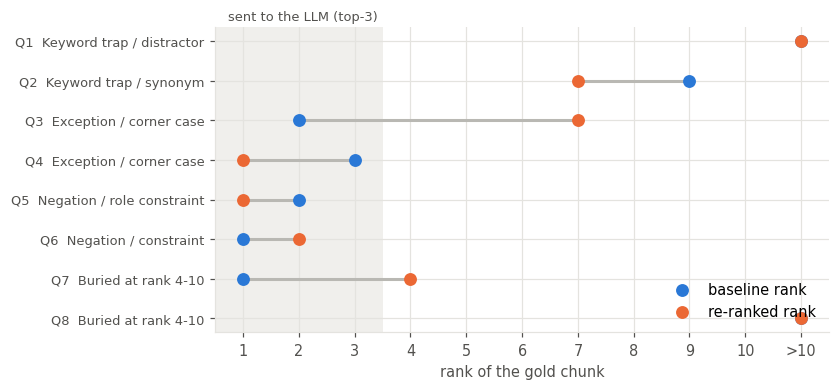

In [19]:
# Dumbbell chart: where the gold chunk sits before (blue) and after (orange) re-ranking.
fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.axvspan(0.5, TOP_N + 0.5, color="#f0efec", zorder=0, lw=0)
ax.text(TOP_N + 0.42, -0.62, "sent to the LLM (top-3)", ha="right", va="center", color=INK_2, fontsize=8.5)
for y, r in enumerate(stress_results):
    b, a = r["base_rank"] or TOP_K + 1, r["rr_rank"] or TOP_K + 1
    ax.plot([b, a], [y, y], color="#b9b8b3", lw=2, zorder=1)
    ax.scatter(b, y, color=C_BASE, s=55, zorder=2, label="baseline rank" if y == 0 else None)
    ax.scatter(a, y, color=C_RERANK, s=55, zorder=3, label="re-ranked rank" if y == 0 else None)
ax.set_yticks(range(len(stress_results)))
ax.set_yticklabels([f"{r['id']}  {r['category'][:26]}" for r in stress_results], fontsize=8.5)
ax.set_xticks(range(1, TOP_K + 2))
ax.set_xticklabels([str(i) for i in range(1, TOP_K + 1)] + [">10"])
ax.set_xlim(0.5, TOP_K + 1.5)
ax.invert_yaxis()
ax.set_xlabel("rank of the gold chunk")
ax.legend(loc="lower right")
plt.show()

## 9. Where re-ranking does *not* help

Two honest counter-examples, so the conclusion is not over-sold:

* **L1 - an abstract negated question.** The Cross-Encoder was trained on web search queries (MS MARCO), so it may prefer passages that talk about the topic in general over the one that lists the exceptions.
* **L2 - recall ceiling.** If the gold chunk is not in the Stage-1 Top 10, the re-ranker never sees it and cannot rescue it. `full_bi_rank` shows how far down the Bi-Encoder ranked it.

In [20]:
LIMIT_QUERIES = [{'id': 'L1',
  'category': 'Re-ranker may demote (abstract negated question)',
  'query': 'Which ways of getting out are not possible on a no ball?',
  'gold': ['except 34 (Hit the ball twice)'],
  'expected': 'Law 21.17: on a No ball neither batter can be out except Hit the ball twice (34), Obstructing the field (37) or '
              'Run out (38).'},
 {'id': 'L2',
  'category': 'Recall ceiling (gold chunk may never reach the Top 10)',
  'query': 'What happens if the bowler throws the ball while bowling?',
  'gold': ['in the opinion of either umpire the ball has been thrown'],
  'expected': 'Law 21.3: No ball is called and the bowler gets a first and final warning; a further thrown delivery in that '
              'innings means suspension from bowling for the rest of the innings.'}]

In [21]:
limit_results = []
for lq in LIMIT_QUERIES:
    gold = gold_ids(lq["gold"])
    res = run_both_pipelines(lq["query"])
    res.update(lq)
    res["gold_ids"] = sorted(gold)
    res["gold_refs"] = sorted({chunk_df.ref[g] for g in gold})
    res["base_rank"], res["rr_rank"] = rank_of(res["base_ids"], gold), rank_of(res["rr_ids"], gold)
    res["full_bi_rank"] = full_bi_rank(lq["query"], gold)
    res["table"] = rank_table(res, gold)
    limit_results.append(res)
    show_stress(res)
    print(f"\nBi-Encoder rank of the gold chunk among all {len(chunks)} chunks: #{res['full_bi_rank']}\n" + "=" * 80)

### L1 - Re-ranker may demote (abstract negated question)
**Query:** Which ways of getting out are not possible on a no ball?  
**Gold chunk:** Law 21.15-21.17 - **Rank shift: #3 -> #5**  
**Correct answer (from the Laws):** Law 21.17: on a No ball neither batter can be out except Hit the ball twice (34), Obstructing the field (37) or Run out (38).

,chunk,cosine,CE score,rerank rank,shift,gold,-> P1 LLM,-> P2 LLM
base rank,,,,,,,,
1,Law 38.3,0.543,3.24,1,0,,x,x
2,Law 21.7-21.8,0.512,-2.29,9,-7,,x,
3,Law 21.15-21.17,0.511,1.01,5,-2,GOLD,x,
4,Law 21.5,0.511,0.81,6,-2,,,
5,Law 37.1-37.3,0.508,1.80,2,3,,,x
6,Law 37.3-37.5,0.489,1.24,4,2,,,
7,Law 38.1-38.2,0.488,0.54,7,0,,,
8,Law 23.3,0.486,-3.03,10,-2,,,
9,Law 20.4,0.484,-1.61,8,1,,,


Answer 1 (baseline top-3: ['Law 38.3', 'Law 21.7-21.8', 'Law 21.15-21.17'])
According to Law 21.17, when a no ball is called, neither batter can be out under any of the Laws except for 34 (Hit the ball twice), 37 (Obstructing the field) or 38 (Run out). [Law 21.17]

Answer 2 (re-ranked top-3: ['Law 38.3', 'Law 37.1-37.3', 'Law 38.3-38.4'])
The provided context does not answer this question.

Bi-Encoder rank of the gold chunk among all 265 chunks: #3


### L2 - Recall ceiling (gold chunk may never reach the Top 10)
**Query:** What happens if the bowler throws the ball while bowling?  
**Gold chunk:** Law 21.3 - **Rank shift: not in top-10 -> not in top-10**  
**Correct answer (from the Laws):** Law 21.3: No ball is called and the bowler gets a first and final warning; a further thrown delivery in that innings means suspension from bowling for the rest of the innings.

,chunk,cosine,CE score,rerank rank,shift,gold,-> P1 LLM,-> P2 LLM
base rank,,,,,,,,
1,Law 38.3,0.643,4.73,1,0,,x,x
2,Law 21.6-21.7,0.634,2.74,5,-3,,x,
3,Law 41.8,0.613,3.15,4,-1,,x,
4,Law 20.4,0.610,1.99,8,-4,,,
5,Law 41.7,0.607,2.58,6,-1,,,
6,Law 17.8,0.597,3.97,2,4,,,x
7,Law 32.1-32.2,0.594,0.61,9,-2,,,
8,Law 41.6,0.592,2.31,7,1,,,
9,Law 21.3,0.589,3.38,3,6,,,x


Answer 1 (baseline top-3: ['Law 38.3', 'Law 21.6-21.7', 'Law 41.8'])
According to Law 38.3.1, if the non-striker is out of their ground at any time from the moment the ball comes into play until the moment the bowler's arm reaches the highest point of their normal bowling action, the non-striker can be out Run out if the ball breaks the wicket. Therefore, if the bowler throws the ball while bowling, it could potentially put the non-striker out if they are out of their ground at that moment. [Law 38.3.1]

Answer 2 (re-ranked top-3: ['Law 38.3', 'Law 17.8', 'Law 21.3'])
According to Law 21.3, if either umpire considers that a further delivery by the same bowler is thrown underarm, they shall call and signal No Ball. This results in the bowler being suspended from bowling immediately and the over being completed by another bowler. [Law 21.3]

Bi-Encoder rank of the gold chunk among all 265 chunks: #27


**Observations on the counter-examples (write after running):**

* **L1:** what happened to the gold chunk's rank? Which chunk did the Cross-Encoder prefer instead, and why might it look more relevant to a model trained on web search?
* **L2:** was the gold chunk inside the Top 10? If not, what in the question (shared words such as *bowler*, *ball*, *umpire*) pulled other passages ahead of it?

If the two queries above do not show these effects in your run, use the "worse" and "missing from top-10" tables in Section 10 to pick better counter-examples and replace them here.

## 10. Retrieval quality on a larger labelled query set

To check that the stress tests are not cherry-picked, we run a larger set of **labelled questions** (the 10 above plus 44 more, covering fielding, dismissals, intervals, penalties, equipment and signals) through both rankers. No LLM is needed here - we only look at where the gold chunk lands.

Metrics: **Hit@1**, **Hit@3** (= the gold chunk reaches the LLM), **MRR@10**, and **Recall@10** (the ceiling: identical for both pipelines by construction, because the Cross-Encoder only re-orders the same 10 candidates).

In [22]:
EXTRA_QUERIES = [('How many people can stand behind square on the leg side?',
  ['there shall not be more than two fielders, other than the wicket-keeper']),
 ('How wide is the strip the ball is bowled on?', ['10 ft/3.05 m in width']),
 ('How high are the stumps?', ['28 in/71.12 cm above the playing surface']),
 ('Who decides whether it is too wet to play?', ['It is solely for the umpires together to decide whether']),
 ('What gets a batter out for knocking their own stumps over?', ['The striker is out Hit wicket if']),
 ('Can the captain declare the innings in any innings of the match?', ['may declare an innings closed']),
 ('Is a short run always penalised?', ['shall disregard the short running']),
 ('Can a replacement player bat in the innings?', ['A replacement shall not bat in an innings in which']),
 ('Does the pitch get rolled before every innings?', ['other than the first innings of the match']),
 ('Is it hit the ball twice if the striker hits it again to send it back to a fielder?',
  ['in order to return the ball to any fielder']),
 ('Which ways of getting out apply on a wide ball?', ['except 35 (Hit wicket)']),
 ('Can the pitch be watered during the match?', ['The pitch shall not be watered during the match']),
 ('Can a substitute fielder bowl or captain the side?', ['A substitute shall not bowl or act as captain']),
 ('Are drinks breaks allowed in the final hour of the match?', ['Intervals for drinks may not be taken during the last hour']),
 ('Is underarm bowling banned?', ['Underarm bowling shall not be permitted except by special agreement']),
 ('Can an umpire give a batter out without an appeal?', ['unless appealed to by a fielder']),
 ('Can the umpires be swapped during the match?', ['An umpire shall not be changed during the match']),
 ('Can a bowler send down two overs in a row?', ['provided they do not bowl two overs consecutively']),
 ('Can a wicket-keeper wear gloves with webbing between the fingers?', ['shall have no webbing between the fingers except']),
 ('Can the umpire fix the stumps straight away if the wicket is broken while the ball is live?',
  ['it shall not be remade by an umpire until the ball is dead']),
 ('How many overs must be bowled in the last hour of a match?', ['minimum of 20 overs which must be bowled']),
 ('After how many overs can the fielding captain ask for a new ball in a multi-day match?',
  ['equal to or greater than 80 overs']),
 ('What lead is needed to enforce the follow-on in a three-day match?', ['150 runs in a match of 3 or 4 days']),
 ('What is the maximum unserved penalty time for a fielder who left the field?', ['limited to a maximum of 90 minutes']),
 ('When is a boundary six scored?', ['A Boundary 6 will be scored if and only if']),
 ('How long does a new batter have to get ready before being timed out?', ['within 3 minutes of the dismissal or retirement']),
 ('What is the shortest allowed non-turf pitch?', ['Length – a minimum of 58 ft/17.68 m']),
 ('How many penalty runs for a helmet on the ground that the ball hits?',
  ['award 5 Penalty runs to the batting side any runs completed']),
 ('How long before the toss may captains toss the coin at the earliest?',
  ['not earlier than 30 minutes, nor later than 15 minutes']),
 ('What is the signal for a wide?', ['Wide – by extending both arms horizontally']),
 ('What happens if the bowler keeps bowling bouncers?',
  ['As soon as the umpire decides that the bowling of short deliveries has become dangerous']),
 ('When can a batter be out for the ball hitting their pad?', ['The striker is out LBW if all the circumstances']),
 ('What happens if a batter deliberately hits the ball with their hand?',
  ['wilfully strikes the ball with a hand not holding the bat']),
 ('What is the punishment for scratching the ball?', ['Regardless of whether a replacement ball has been chosen to be used']),
 ('What if a phone rings and distracts the batter?', ['distracted by any noise or movement']),
 ('What if a dog runs onto the field and the ball hits it?',
  ['A person, animal or object coming onto the field of play while the ball is in play']),
 ('When is a batter allowed someone to run for them?', ['shall allow a runner for a batter if they are satisfied']),
 ('How is a match decided if both teams score the same?',
  ['shall be a Tie when all innings have been completed and the scores are equal']),
 ('How are overs lost to a rain delay in the last hour worked out?',
  ['One over shall be deducted for every complete 3 minutes of time lost']),
 ('Can the captain change the bat or field decision after the toss?', ['whether to bat or to field and shall notify']),
 ("What if the ball gets stuck in a batter's clothing?", ['lodges in the clothing or equipment of a batter']),
 ("What if the bowler's trousers fall down and hit the stumps?", ['any clothing or other object that falls from the bowler']),
 ('When can the non-striker be run out for backing up too far?', ['the non-striker is liable to be Run out']),
 ('What parts of the body can a fielder use to stop the ball?', ['A fielder may field the ball with any part of their person'])]

In [23]:
eval_set = [(d["query"], d["gold"]) for d in STRESS_QUERIES + LIMIT_QUERIES] + EXTRA_QUERIES
eval_rows = []
for q, g in eval_set:
    gold = gold_ids(g)
    if not gold:
        print("skipped (gold phrase not found in any chunk):", q)
        continue
    base_ids, _ = baseline_retrieve(q)
    rr_ids, _ = rerank(q, base_ids)
    eval_rows.append({"query": q, "baseline rank": rank_of(base_ids, gold), "re-ranked rank": rank_of(rr_ids, gold)})
eval_df = pd.DataFrame(eval_rows)


def metrics(col):
    r = eval_df[col]
    return {"Hit@1": (r == 1).mean(), "Hit@3 (reaches LLM)": (r <= TOP_N).mean(),
            "MRR@10": (1 / r).fillna(0).mean(), "Recall@10 (ceiling)": r.notna().mean()}


metrics_df = pd.DataFrame({"Pipeline 1 (Bi-Encoder)": metrics("baseline rank"),
                           "Pipeline 2 (+ Cross-Encoder)": metrics("re-ranked rank")}).round(3)
display(metrics_df)

,Pipeline 1 (Bi-Encoder),Pipeline 2 (+ Cross-Encoder)
Hit@1,0.519,0.611
Hit@3 (reaches LLM),0.722,0.741
MRR@10,0.627,0.686
Recall@10 (ceiling),0.852,0.852


## 11. Latency profiling

We time each stage separately with `time.perf_counter()`, after a warm-up, on the retrieval device (CPU):

* **Bi-Encoder retrieval** = embed the query + FAISS search (shared by both pipelines);
* **Cross-Encoder re-ranking** = score 10 pairs + sort (Pipeline 2 only);
* **LLM generation** = measured during the stress tests above (8 queries x 2 pipelines).

In [27]:
REPEATS = 5   # x len(eval_set) queries
for q, _ in eval_set[:3]:          # warm-up (first calls allocate buffers)
    run_both_pipelines(q, generate=False)

lat = []
for _ in range(REPEATS):
    for q, _ in eval_set:
        r = run_both_pipelines(q, generate=False)
        lat.append({"bi_ms": r["retrieval_ms"], "ce_ms": r["rerank_ms"]})
lat = pd.DataFrame(lat)
lat["p1_retrieval_ms"] = lat["bi_ms"]
lat["p2_retrieval_ms"] = lat["bi_ms"] + lat["ce_ms"]

lat_table = pd.DataFrame({
    "Pipeline 1 (baseline retrieval)": lat["p1_retrieval_ms"].describe()[["mean", "std", "50%"]],
    "Pipeline 2 (retrieval + re-ranking)": lat["p2_retrieval_ms"].describe()[["mean", "std", "50%"]],
    "Cross-Encoder re-ranking only": lat["ce_ms"].describe()[["mean", "std", "50%"]],
}).T.rename(columns={"mean": "mean (ms)", "std": "std (ms)", "50%": "median (ms)"}).round(1)
display(lat_table)
print(f"{len(lat)} timed runs. Re-ranking multiplies retrieval time by {lat['p2_retrieval_ms'].mean() / lat['p1_retrieval_ms'].mean():.1f}x "
      f"(adds {lat['ce_ms'].mean():.1f} ms).")

,mean (ms),std (ms),median (ms)
Pipeline 1 (baseline retrieval),7.9,0.5,7.9
Pipeline 2 (retrieval + re-ranking),102.5,10.7,101.8
Cross-Encoder re-ranking only,94.6,10.6,93.9


270 timed runs. Re-ranking multiplies retrieval time by 13.0x (adds 94.6 ms).


In [28]:
gen = pd.DataFrame([{"pipeline": p, "gen_s": r[p]["gen_s"]} for r in stress_results for p in ("p1", "p2")])
p1_e2e = lat["p1_retrieval_ms"].mean() + gen[gen.pipeline == "p1"].gen_s.mean() * 1e3
p2_e2e = lat["p2_retrieval_ms"].mean() + gen[gen.pipeline == "p2"].gen_s.mean() * 1e3
e2e_df = pd.DataFrame({
    "retrieval (ms)": [lat["p1_retrieval_ms"].mean(), lat["p2_retrieval_ms"].mean()],
    "LLM generation (ms)": [gen[gen.pipeline == "p1"].gen_s.mean() * 1e3, gen[gen.pipeline == "p2"].gen_s.mean() * 1e3],
    "end-to-end (ms)": [p1_e2e, p2_e2e],
}, index=["Pipeline 1", "Pipeline 2"]).round(1)
e2e_df["retrieval share"] = (e2e_df["retrieval (ms)"] / e2e_df["end-to-end (ms)"]).map("{:.1%}".format)
display(e2e_df)
print("LLM time depends on prompt and answer length, not on the retriever; re-ranking adds the same few dozen ms to every query.")

,retrieval (ms),LLM generation (ms),end-to-end (ms),retrieval share
Pipeline 1,7.9,691.5,699.4,1.1%
Pipeline 2,102.5,918.4,1020.9,10.0%


LLM time depends on prompt and answer length, not on the retriever; re-ranking adds the same few dozen ms to every query.


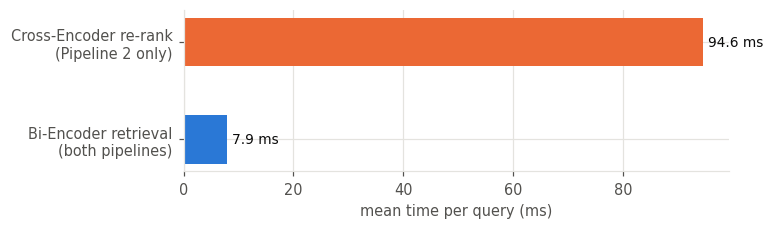

In [29]:
fig, ax = plt.subplots(figsize=(6.4, 1.9))
vals = [lat["bi_ms"].mean(), lat["ce_ms"].mean()]
labels = ["Bi-Encoder retrieval\n(both pipelines)", "Cross-Encoder re-rank\n(Pipeline 2 only)"]
bars = ax.barh(labels, vals, color=[C_BASE, C_RERANK], height=0.5)
for b, v in zip(bars, vals):
    ax.text(v + max(vals) * 0.01, b.get_y() + b.get_height() / 2, f"{v:.1f} ms", va="center", fontsize=9, color=INK)
ax.set_xlabel("mean time per query (ms)")
plt.show()

## 12. Scaling: why not run the Cross-Encoder over everything?

The Bi-Encoder pays for document encoding **once, offline**; a query costs one encoder pass plus a vector search.
The Cross-Encoder has no reusable document representation: every query needs one full transformer pass **per chunk**.
We measure the Cross-Encoder cost as the number of candidates grows, extrapolate it to larger corpora, and compare it with exact vector search over up to 1M vectors.

In [30]:
probe_queries = [d["query"] for d in STRESS_QUERIES[:3]]
ce_cost = []
for n in [10, 25, 50, 100, 200, len(chunks)]:
    times = []
    for q in probe_queries:
        ids = list(range(n))
        t0 = time.perf_counter()
        cross_encoder.predict([(q, chunk_texts[i]) for i in ids], batch_size=32, show_progress_bar=False)
        times.append((time.perf_counter() - t0) * 1e3)
    ce_cost.append({"candidates": n, "cross-encoder ms": float(np.mean(times))})
ce_cost = pd.DataFrame(ce_cost)
display(ce_cost.round(1))

per_pair_ms = ce_cost["cross-encoder ms"].iloc[-1] / ce_cost["candidates"].iloc[-1]
bi_ms = lat["bi_ms"].mean()
print(f"Cross-Encoder cost = {per_pair_ms:.2f} ms per (query, chunk) pair, growing linearly with the number of chunks.")
print(f"Bi-Encoder query + FAISS = {bi_ms:.1f} ms; one-off offline indexing of all {len(chunks)} chunks = {index_time:.1f} s.")

,candidates,cross-encoder ms
0,10,114.0
1,25,335.8
2,50,593.2
3,100,1359.4
4,200,2583.0
5,265,3391.5


Cross-Encoder cost = 12.80 ms per (query, chunk) pair, growing linearly with the number of chunks.
Bi-Encoder query + FAISS = 7.9 ms; one-off offline indexing of all 265 chunks = 2.2 s.


In [31]:
# Synthetic large corpus: exact FAISS search over random unit vectors vs. a Cross-Encoder extrapolation.
BIG_N = 1_000_000          # reduce to 500_000 if Colab runs out of RAM (1M x 384 floats = about 1.5 GB)
rng = np.random.default_rng(SEED)
big_index = faiss.IndexFlatIP(384)
for _ in range(BIG_N // 100_000):                      # add in 100k batches to keep peak memory low
    block = rng.standard_normal((100_000, 384), dtype=np.float32)
    block /= np.linalg.norm(block, axis=1, keepdims=True)
    big_index.add(block)
qv = rng.standard_normal((1, 384), dtype=np.float32)
qv /= np.linalg.norm(qv)
big_index.search(qv, TOP_K)                            # warm-up
t0 = time.perf_counter()
for _ in range(5):
    big_index.search(qv, TOP_K)
big_ms = (time.perf_counter() - t0) / 5 * 1e3
del big_index

scaling_df = pd.DataFrame({
    "corpus size (chunks)": [len(chunks), 10_000, 100_000, BIG_N],
    "Cross-Encoder on ALL chunks (extrapolated)": [f"{n * per_pair_ms / 1e3:,.1f} s per query" for n in [len(chunks), 10_000, 100_000, BIG_N]],
})
display(scaling_df)
print(f"Exact FAISS search over {BIG_N:,} vectors: {big_ms:.0f} ms per query.")
print(f"Two-stage design: Bi-Encoder + FAISS + Cross-Encoder on only {TOP_K} candidates = about {bi_ms + TOP_K * per_pair_ms:.0f} ms, whatever the corpus size.")

,corpus size (chunks),Cross-Encoder on ALL chunks (extrapolated)
0,265,3.4 s per query
1,10000,128.0 s per query
2,100000,"1,279.8 s per query"
3,1000000,"12,798.0 s per query"


Exact FAISS search over 1,000,000 vectors: 87 ms per query.
Two-stage design: Bi-Encoder + FAISS + Cross-Encoder on only 10 candidates = about 136 ms, whatever the corpus size.


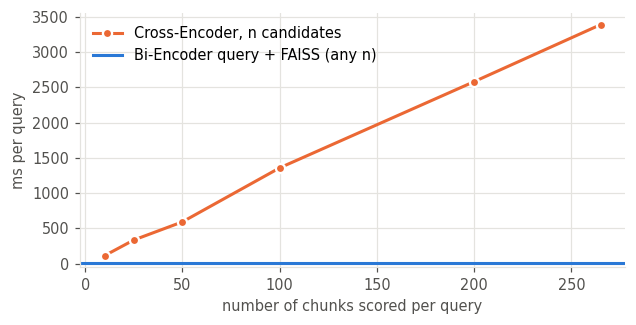

In [32]:
fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.plot(ce_cost["candidates"], ce_cost["cross-encoder ms"], color=C_RERANK, lw=2, marker="o", ms=6,
        markeredgecolor="white", markeredgewidth=1.5, label="Cross-Encoder, n candidates")
ax.axhline(bi_ms, color=C_BASE, lw=2, label="Bi-Encoder query + FAISS (any n)")
ax.set_xlabel("number of chunks scored per query"); ax.set_ylabel("ms per query")
ax.legend(loc="upper left")
plt.show()

In [33]:
# Would an "exhaustive" Cross-Encoder fix the recall-ceiling query L2 - and at what cost?
l2 = limit_results[1]
t0 = time.perf_counter()
all_scores = cross_encoder.predict([(l2["query"], t) for t in chunk_texts], batch_size=32, show_progress_bar=False)
ce_all_s = time.perf_counter() - t0
ce_full_rank = min(int((all_scores > all_scores[g]).sum()) + 1 for g in l2["gold_ids"])
print(f"L2 '{l2['query']}'\n  gold {l2['gold_refs']}: Bi-Encoder rank #{l2['full_bi_rank']} of {len(chunks)}, "
      f"Cross-Encoder over ALL chunks rank #{ce_full_rank}.")
print(f"  Scoring all {len(chunks)} chunks took {ce_all_s:.1f} s for ONE query (vs {l2['retrieval_ms'] + l2['rerank_ms']:.0f} ms for the two-stage pipeline), "
      f"and it grows linearly with the corpus.")

L2 'What happens if the bowler throws the ball while bowling?'
  gold ['Law 21.3']: Bi-Encoder rank #27 of 265, Cross-Encoder over ALL chunks rank #5.
  Scoring all 265 chunks took 3.3 s for ONE query (vs 165 ms for the two-stage pipeline), and it grows linearly with the corpus.


## 13. Save outputs

In [35]:
def slim(r):
    return {"id": r["id"], "category": r["category"], "query": r["query"], "gold": r["gold_refs"], "expected": r["expected"],
            "baseline_rank": r["base_rank"], "reranked_rank": r["rr_rank"], "full_bi_rank": r["full_bi_rank"],
            "p1_context": [chunk_df.ref[i] for i in r["base_ids"][:TOP_N]], "p2_context": [chunk_df.ref[i] for i in r["rr_ids"][:TOP_N]],
            "answer_1": r["p1"]["answer"], "answer_2": r["p2"]["answer"],
            "gen_s_1": round(r["p1"]["gen_s"], 2), "gen_s_2": round(r["p2"]["gen_s"], 2)}


(RESULTS_DIR / "stress_results.json").write_text(json.dumps(
    {"config": {"bi_encoder": BI_ENCODER_NAME, "cross_encoder": CROSS_ENCODER_NAME, "llm": LLM_NAME,
                "top_k": TOP_K, "top_n": TOP_N, "n_chunks": len(chunks)},
     "stress": [slim(r) for r in stress_results], "counter_examples": [slim(r) for r in limit_results]}, indent=2))
shift_df.to_csv(RESULTS_DIR / "rank_shifts.csv")
eval_df.to_csv(RESULTS_DIR / "labelled_eval.csv", index=False)
metrics_df.to_csv(RESULTS_DIR / "retrieval_metrics.csv")
lat_table.to_csv(RESULTS_DIR / "latency_table.csv")
e2e_df.to_csv(RESULTS_DIR / "end_to_end_latency.csv")
print("saved:", sorted(p.name for p in RESULTS_DIR.iterdir()))

saved: ['end_to_end_latency.csv', 'labelled_eval.csv', 'latency_table.csv', 'rank_shifts.csv', 'retrieval_metrics.csv', 'stress_results.json']


## 14. Summary

In [36]:
summary = pd.DataFrame({
    "Pipeline 1 (Bi-Encoder)": [metrics_df.loc["Hit@3 (reaches LLM)", "Pipeline 1 (Bi-Encoder)"], metrics_df.loc["Hit@1", "Pipeline 1 (Bi-Encoder)"],
                                metrics_df.loc["MRR@10", "Pipeline 1 (Bi-Encoder)"], metrics_df.loc["Recall@10 (ceiling)", "Pipeline 1 (Bi-Encoder)"],
                                f"{shift_df['gold in P1 context'].sum()}/{len(shift_df)}", f"{lat['p1_retrieval_ms'].mean():.1f} ms"],
    "Pipeline 2 (+ Cross-Encoder)": [metrics_df.loc["Hit@3 (reaches LLM)", "Pipeline 2 (+ Cross-Encoder)"], metrics_df.loc["Hit@1", "Pipeline 2 (+ Cross-Encoder)"],
                                     metrics_df.loc["MRR@10", "Pipeline 2 (+ Cross-Encoder)"], metrics_df.loc["Recall@10 (ceiling)", "Pipeline 2 (+ Cross-Encoder)"],
                                     f"{shift_df['gold in P2 context'].sum()}/{len(shift_df)}", f"{lat['p2_retrieval_ms'].mean():.1f} ms"],
}, index=[f"Hit@3 ({len(eval_df)} labelled queries)", "Hit@1", "MRR@10", "Recall@10 (ceiling)", "Stress queries: gold in LLM context", "Retrieval latency per query"])
display(summary)
print(f"Queries rescued by re-ranking (rank 4-10 -> top-3): {len(rescued_q)} of {len(eval_df)} labelled, {len(rescued)} of {len(stress_results)} stress queries.")

,Pipeline 1 (Bi-Encoder),Pipeline 2 (+ Cross-Encoder)
Hit@3 (54 labelled queries),0.722,0.741
Hit@1,0.519,0.611
MRR@10,0.627,0.686
Recall@10 (ceiling),0.852,0.852
Stress queries: gold in LLM context,5/8,3/8
Retrieval latency per query,7.9 ms,102.5 ms


Queries rescued by re-ranking (rank 4-10 -> top-3): 6 of 54 labelled, 0 of 8 stress queries.
